In [1]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
col_dict = {0: 'red', 1: 'blue', 2: 'green', 3: 'orange', 4:'purple', 5:'black', 6:'yellow', 7:'pink', 8:'lightblue',9:'lime', 10:'sienna',11:'indigo'}

## First scenario

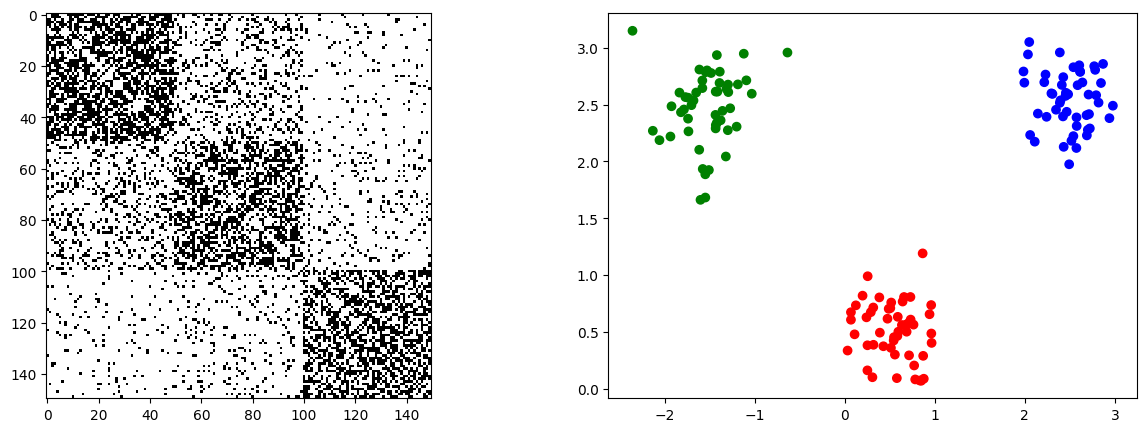

In [2]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)

Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

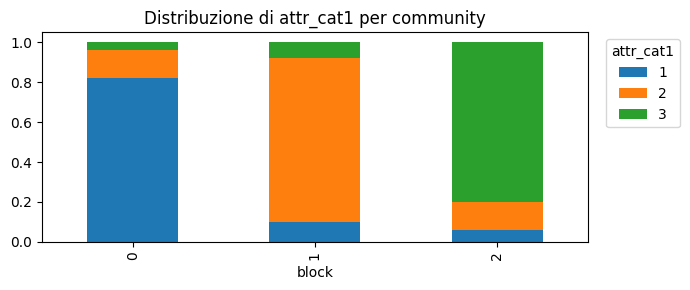

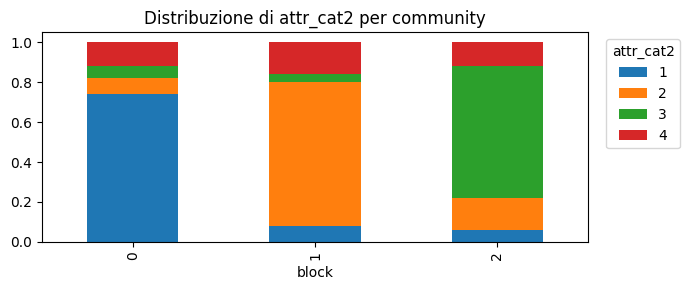

In [3]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [4]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW_old
from vem_sbm_new_version_VICL import VEM_SBM as VEM_SBM_NEW_vicl


Ks = [2,3,4,5]
Rs1 = {}
Rs2 = {}

for K in Ks:
    fit1 = VEM_SBM_NEW_old(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    fit2 = VEM_SBM_NEW_vicl(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs1[K] = fit1
    Rs2[K] = fit2
    print(K)

2
3
4
5


In [5]:
[Rs1[k]['vICL'] for k in Rs1.keys()]

[-6692.664748378996, -5687.97440338049, -5708.194475665612, -5710.484887640077]

In [6]:
[Rs2[k]['vICL'] for k in Rs2.keys()]

[-6146.885951235567, -5687.97440338049, -5718.075386831735, -5736.348059443104]

In [ ]:
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)

In [26]:
Rs[3]['Sigma_list']

[array([[ 0.06303464, -0.00647587],
        [-0.00647587,  0.06060719]]),
 array([[0.0858896 , 0.01480408],
        [0.01480408, 0.10052938]]),
 array([[ 0.06775767, -0.00983409],
        [-0.00983409,  0.06245755]])]

In [5]:
for K in Ks:
    print(Rs[K]['vICL'])

-6151.921109964291
-5714.980896212998
-5759.87263835149
-5784.123283272583


In [6]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

In [9]:
pred_labels_sbm

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [7]:
Rs[3]['Theta']

array([[0.50122449, 0.1016    , 0.2128    ],
       [0.1016    , 0.50530612, 0.0536    ],
       [0.2128    , 0.0536    , 0.5877551 ]])

In [10]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)
# perm[k] = estimated label that corresponds to true block k

# Reorder Theta to match true label order
Theta_est = Rs[3]['Theta']
Theta_aligned = Theta_est[np.ix_(perm, perm)]
print('True:\n', np.array(probs))
print('Estimated (aligned):\n', np.round(Theta_aligned, 3))

True:
 [[0.6  0.2  0.05]
 [0.2  0.5  0.1 ]
 [0.05 0.1  0.5 ]]
Estimated (aligned):
 [[0.588 0.213 0.054]
 [0.213 0.501 0.102]
 [0.054 0.102 0.505]]


In [11]:
perm

array([2, 0, 1])

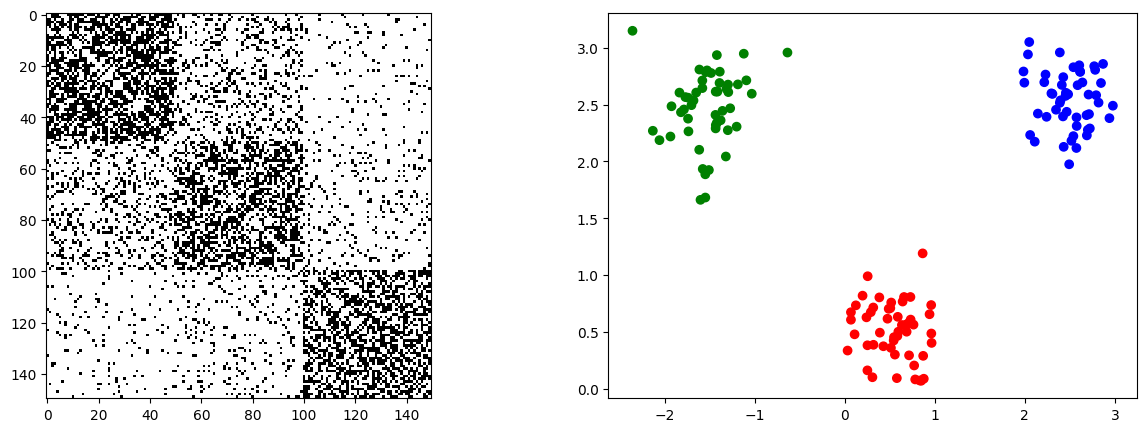

In [22]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)

Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()

labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

In [ ]:
Xg=np.zeros((150,2))
Xg[:50,] = np.random.multivariate_normal(mean=[0.5, 0.5], cov=[[0.08, 0.001], [0.001, 0.08]], size=50)
Xg[50:100,] = np.random.multivariate_normal(mean=[2.5, 2.5], cov=[[0.07, 0.002], [0.002, 0.07]], size=50)
Xg[100:,] = np.random.multivariate_normal(mean=[-1.5, 2.5], cov=[[0.08, 0.003], [0.003, 0.08]], size=50)